In [112]:
import pandas as pd
bikes = pd.read_csv("bikes.csv")
bikes.head()

,temperature,humidity,windspeed,rentals
0,46.716528,0.815969,13.669663,985
1,48.350239,0.800497,15.199782,801
2,34.212394,0.592097,13.247558,1349
3,34.520000,0.623196,11.687963,1562
4,36.800562,0.624643,13.148281,1600


In [113]:
bikes.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   temperature  731 non-null    float64
 1   humidity     731 non-null    float64
 2   windspeed    731 non-null    float64
 3   rentals      731 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 23.0 KB


In [114]:
bikes.describe()

,temperature,humidity,windspeed,rentals
count,731.000000,731.000000,731.000000,731.000000
mean,59.509553,0.486937,9.238886,4504.348837
std,15.486114,0.185415,3.379815,1937.211452
min,22.602432,0.000000,0.932208,22.000000
25%,46.117264,0.353548,6.863568,3152.000000
50%,59.758972,0.502227,9.503508,4548.000000
75%,73.048236,0.624671,11.814559,5956.000000
max,90.497028,0.972500,21.126627,8714.000000


We want to see what type of relationship the data have for one another

<Axes: xlabel='temperature', ylabel='rentals'>

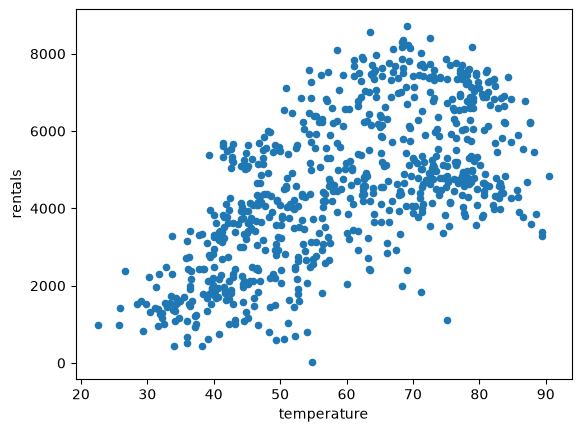

In [115]:
import matplotlib.pyplot as plt
bikes.plot(kind="scatter", x="temperature", y="rentals")

<Axes: xlabel='humidity', ylabel='rentals'>

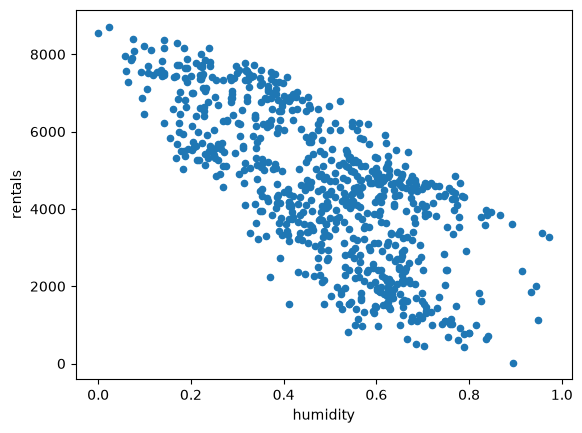

In [116]:
bikes.plot(kind="scatter", x="humidity", y="rentals")

<Axes: xlabel='windspeed', ylabel='rentals'>

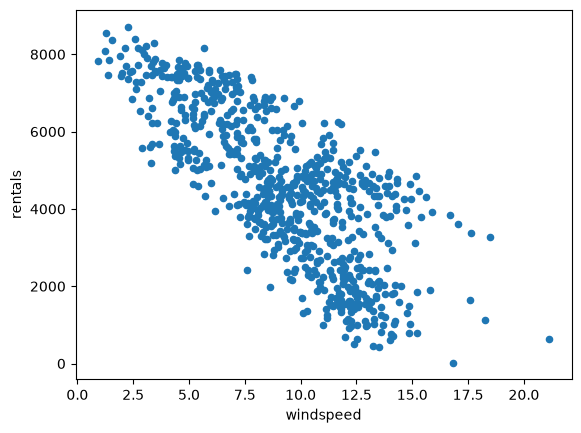

In [117]:
bikes.plot(kind="scatter", x="windspeed", y="rentals")

We can see each relationship with rentals have a more linear regression relation either pos or neg. This indicates we should use a linear regression model for this dataset.

We first split the dataset into the input and output sets as x and y respectively.

In [118]:
response = "rentals"
y = bikes[[response]] #Double brackets cause we want a DataFrame not a 2d list
y

,rentals
0,985
1,801
2,1349
3,1562
4,1600
...,...
726,2114
727,3095
728,1341
729,1796


In [119]:
predictors = list(bikes.columns) #get the name of the columns like the y
predictors.remove(response) #remove the response column name
x = bikes[predictors] #get a 2d list of the names of the predictors. Since it is just names DataFrame is not needed
x

,temperature,humidity,windspeed
0,46.716528,0.815969,13.669663
1,48.350239,0.800497,15.199782
2,34.212394,0.592097,13.247558
3,34.520000,0.623196,11.687963
4,36.800562,0.624643,13.148281
...,...,...,...
726,39.102528,0.482493,10.801229
727,39.031972,0.480433,8.996301
728,39.031972,0.717730,11.829425
729,39.243472,0.523039,12.805314


Now that we have seperated the data we can split the input and output data into the training and testing data

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=1234) #random state makes the randomization a set shuffle amount so the data is always in the same order every time

Now we import a linear regression model and give it the training parameters

In [121]:
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(x_train, y_train)

In [122]:
model.intercept_

array([3800.68469948])

In [123]:
model.coef_

array([[   80.35314543, -4665.73867387,  -196.21650368]])

The intercept is the y intercept and the coef gives the coefficient of each of the input data parameters to give us the output (so 80 for temp, -4665 for humidity, and -196 for windspeed).

Now lets test our model using the test data and see how accurate it is to the real answers

In [124]:
model.score(x_test, y_test)

0.9820623857913312

In [125]:
y_pred = model.predict(x_test)

In [126]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_test, y_pred)

194.31620720519655

This mean that our model is about 98% accurate and has about a +- 194 range from our original answers.